In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:

# ============================================================
# SATELLITE IMAGE CHANGE DETECTION — IMPORTS
# ============================================================

# 1. General Utilities
import os
import random
from pathlib import Path

# 2. Data Processing
import numpy as np
import pandas as pd
import cv2
from PIL import Image

# 3. Visualization
import matplotlib.pyplot as plt

# 4. PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# 5. CNN Encoders
import torchvision.models as models

# 6. Image Augmentation
import albumentations as A
from albumentations.pytorch import ToTensorV2

# 7. Data Splitting & Evaluation
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    jaccard_score
)

# 8. Training Utilities
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from tqdm.auto import tqdm

# 9. GPU Configuration
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 60)
print("SATELLITE CHANGE DETECTION — ENVIRONMENT")
print("=" * 60)

print("PyTorch Version:", torch.__version__)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("All imports completed successfully!")


SATELLITE CHANGE DETECTION — ENVIRONMENT
PyTorch Version: 2.11.0+cu128
Device: cuda
GPU: Tesla T4
All imports completed successfully!


LEVIR-CD+ DATASET OVERVIEW
train/A: 637 images
train/B: 637 images
train/label: 637 images
test/A: 348 images
test/B: 348 images
test/label: 348 images

Matched Training Triplets: 637
Unmatched A: 0
Unmatched B: 0
Unmatched Masks: 0

SAMPLE IMAGE INFORMATION

Sample: train_201.png
Before Shape: (1024, 1024, 3)
After Shape : (1024, 1024, 3)
Mask Shape  : (1024, 1024)
Mask Values : [  0 255]
Changed Area: 5.144 %

Sample: train_121.png
Before Shape: (1024, 1024, 3)
After Shape : (1024, 1024, 3)
Mask Shape  : (1024, 1024)
Mask Values : [  0 255]
Changed Area: 9.404 %

Sample: train_352.png
Before Shape: (1024, 1024, 3)
After Shape : (1024, 1024, 3)
Mask Shape  : (1024, 1024)
Mask Values : [  0 255]
Changed Area: 9.362 %

Sample: train_324.png
Before Shape: (1024, 1024, 3)
After Shape : (1024, 1024, 3)
Mask Shape  : (1024, 1024)
Mask Values : [  0 255]
Changed Area: 0.509 %

Sample: train_304.png
Before Shape: (1024, 1024, 3)
After Shape : (1024, 1024, 3)
Mask Shape  : (1024, 1024)
Mask Va

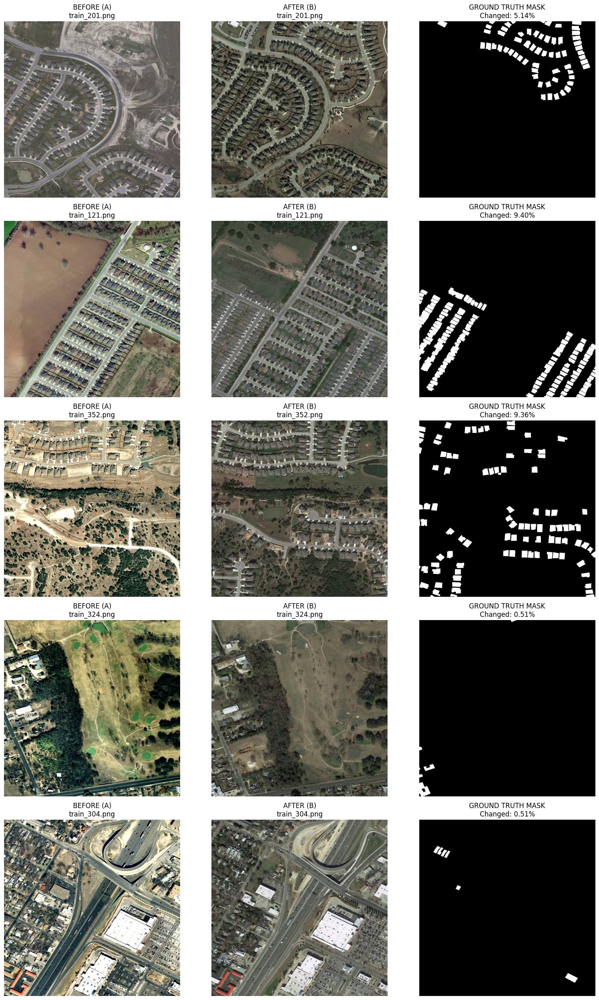


DATASET VISUALIZATION COMPLETED!


In [2]:

# ============================================================
# LEVIR-CD+ — DATASET VISUALIZATION
# ============================================================

from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import random

# Dataset Path
DATASET_PATH = Path(
    "/kaggle/input/datasets/mdrifaturrahman33/"
    "levir-cd-change-detection/LEVIR-CD+"
)

random.seed(42)

# ============================================================
# 1. DATASET STRUCTURE
# ============================================================

print("=" * 65)
print("LEVIR-CD+ DATASET OVERVIEW")
print("=" * 65)

for split in ["train", "test"]:

    split_path = DATASET_PATH / split

    for folder in ["A", "B", "label"]:

        files = list((split_path / folder).glob("*.png"))

        print(f"{split}/{folder}: {len(files)} images")

# ============================================================
# 2. SELECT RANDOM TRAINING SAMPLES
# ============================================================

train_path = DATASET_PATH / "train"

a_files = {p.name for p in (train_path / "A").glob("*.png")}
b_files = {p.name for p in (train_path / "B").glob("*.png")}
m_files = {p.name for p in (train_path / "label").glob("*.png")}

matched_files = sorted(a_files & b_files & m_files)

print("\nMatched Training Triplets:", len(matched_files))
print("Unmatched A:", len(a_files - set(matched_files)))
print("Unmatched B:", len(b_files - set(matched_files)))
print("Unmatched Masks:", len(m_files - set(matched_files)))

sample_files = random.sample(
    matched_files, min(5, len(matched_files))
)

# ============================================================
# 3. VISUALIZE BEFORE / AFTER / MASK
# ============================================================

fig, axes = plt.subplots(
    len(sample_files),
    3,
    figsize=(16, 5 * len(sample_files)),
    squeeze=False
)

print("\n" + "=" * 65)
print("SAMPLE IMAGE INFORMATION")
print("=" * 65)

for i, filename in enumerate(sample_files):

    before = np.array(
        Image.open(train_path / "A" / filename).convert("RGB")
    )

    after = np.array(
        Image.open(train_path / "B" / filename).convert("RGB")
    )

    mask = np.array(
        Image.open(train_path / "label" / filename).convert("L")
    )

    changed = mask > 127

    change_pct = changed.mean() * 100

    print(f"\nSample: {filename}")
    print("Before Shape:", before.shape)
    print("After Shape :", after.shape)
    print("Mask Shape  :", mask.shape)
    print("Mask Values :", np.unique(mask))
    print("Changed Area:", round(change_pct, 3), "%")

    axes[i, 0].imshow(before)
    axes[i, 0].set_title(f"BEFORE (A)\n{filename}")

    axes[i, 1].imshow(after)
    axes[i, 1].set_title(f"AFTER (B)\n{filename}")

    axes[i, 2].imshow(
        changed,
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[i, 2].set_title(
        f"GROUND TRUTH MASK\nChanged: {change_pct:.2f}%"
    )

    for ax in axes[i]:
        ax.axis("off")

plt.tight_layout()
plt.show()

print("\n" + "=" * 65)
print("DATASET VISUALIZATION COMPLETED!")
print("=" * 65)


LEVIR-CD+ | DATASET INTEGRITY
TRAIN | Before(A):  637 | After(B):  637 | Mask:  637 | Matched:  637
TEST  | Before(A):  348 | After(B):  348 | Mask:  348 | Matched:  348
Filename overlap between train and test: 0
Test labels will NOT be opened.


Full TRAIN EDA:   0%|          | 0/637 [00:00<?, ?it/s]


1. TRAINING IMAGE / MASK QUALITY
Matched Training Triplets: 637
Successfully Analyzed: 637
Issues Flagged: 32
Image Sizes: {(1024, 1024): 637}
Mask Pixel Values: [0, 156, 254, 255]
Identical Before/After Pairs: 0


,Filename,Issue
0,train_100.png,"Non-binary mask values: [0, 156, 255]"
1,train_101.png,"Non-binary mask values: [0, 156, 255]"
2,train_218.png,"Non-binary mask values: [0, 254, 255]"
3,train_263.png,"Non-binary mask values: [0, 254, 255]"
4,train_271.png,"Non-binary mask values: [0, 156, 255]"
5,train_272.png,"Non-binary mask values: [0, 156, 255]"
6,train_273.png,"Non-binary mask values: [0, 156, 255]"
7,train_275.png,"Non-binary mask values: [0, 156, 255]"
8,train_278.png,"Non-binary mask values: [0, 156, 255]"
9,train_279.png,"Non-binary mask values: [0, 156, 255]"



2. GLOBAL PIXEL CLASS BALANCE
Changed Pixels: 31,066,643 (4.651%)
Unchanged Pixels: 636,876,269 (95.349%)
Negative / Positive Ratio: 20.5
Completely Unchanged Masks: 65
Images with Change < 1%: 202
Images with Change >= 10%: 96
All-No-Change Pixel Accuracy: 95.349 % (misleading baseline)

3. PER-IMAGE STATISTICS


...


4. PATCH DISTRIBUTION (256 x 256)
Total Patches: 10192
Zero-Change Patches: 5,654 (55.47%)
Changed Patches: 4,538 (44.53%)
Patches with >= 1% Change: 3879
Patches with >= 5% Change: 2642
Patches with >= 10% Change: 1822

Patch-Level Change Statistics:


count    10192.000
mean         4.651
std          8.469
min          0.000
25%          0.000
50%          0.000
75%          5.391
90%         18.283
95%         25.262
99%         33.252
max         70.485
Name: Change %, dtype: float64


Nonempty Patch Count per Image:


,Images
Nonempty Patches,
0,65
1,34
2,39
3,34
4,46
5,47
6,47
7,30
8,32



5. CHANGED REGION COMPONENT ANALYSIS
Total Connected Components: 31291
Tiny Components (<=10 pixels): 158
Region Area Percentiles: [ 448.   657.   849.  1090.  1429.  3656.4]


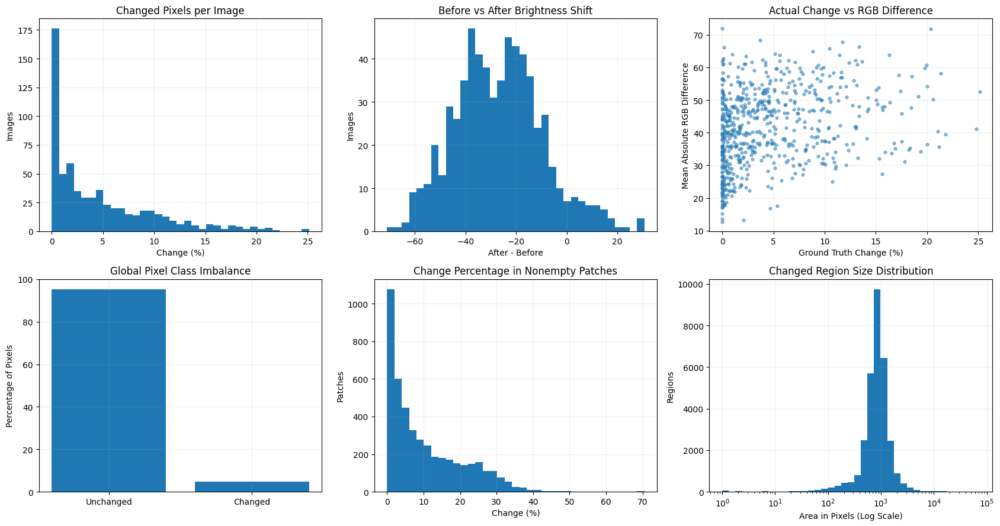


6. REPRESENTATIVE BEFORE / AFTER / MASK / OVERLAY


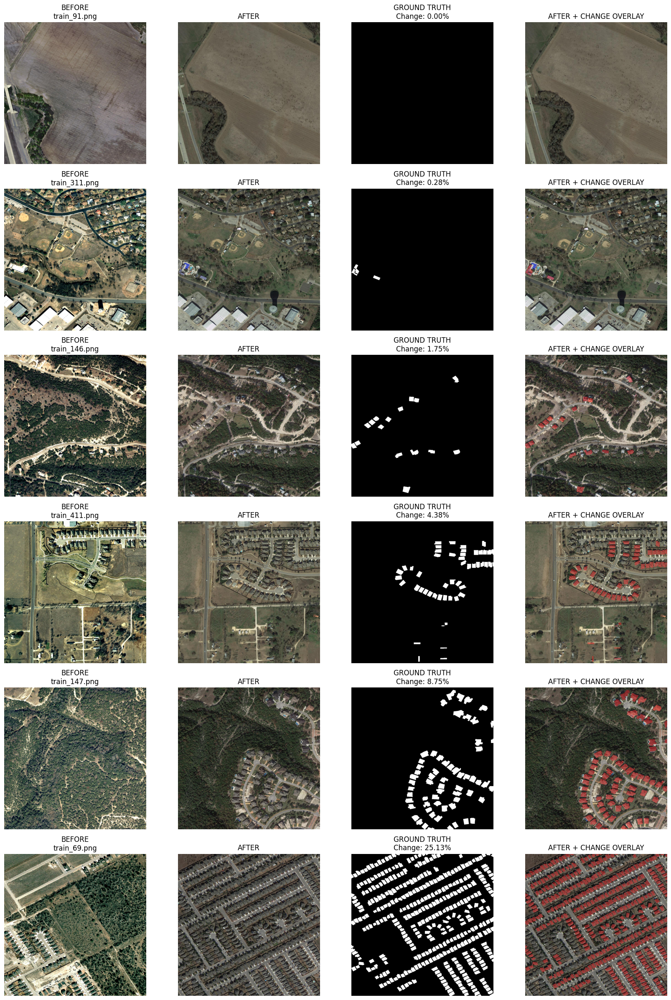


FULL DATASET EDA COMPLETED SUCCESSFULLY!
Training Image Pairs Analyzed: 637
Total Training Pixels: 667,942,912
Global Changed Pixel Rate: 4.651 %
Global Unchanged Pixel Rate: 95.349 %
Total 256x256 Patches: 10192
Data Quality Issues: 32

Test Labels: NOT USED
No Output Files Created


In [3]:

# ================================================================
# LEVIR-CD+ : FULL DATASET EDA
# Image Quality | Class Imbalance | Patch Analysis | Visualization
# Test labels remain untouched
# ================================================================

from pathlib import Path
from collections import Counter
import hashlib
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from IPython.display import display

# ================================================================
# 1. CONFIGURATION
# ================================================================

ROOT = Path(
    "/kaggle/input/datasets/mdrifaturrahman33/"
    "levir-cd-change-detection/LEVIR-CD+"
)

PATCH = 256
SHOW_SAMPLES = 6
ANALYZE_COMPONENTS = True
MASK_THRESHOLD = 127

assert ROOT.is_dir(), f"Dataset folder not found: {ROOT}"

# ================================================================
# 2. DATASET INTEGRITY
# ================================================================

def png_names(split, folder):

    p = ROOT / split / folder

    if not p.is_dir():
        raise FileNotFoundError(f"Missing folder: {p}")

    return {f.name for f in p.glob("*.png")}


name_sets = {
    (s, part): png_names(s, part)
    for s in ("train", "test")
    for part in ("A", "B", "label")
}

print("=" * 72)
print("LEVIR-CD+ | DATASET INTEGRITY")
print("=" * 72)

for split in ("train", "test"):

    a, b, m = (
        name_sets[split, p]
        for p in ("A", "B", "label")
    )

    common = a & b & m

    print(
        f"{split.upper():5s} | "
        f"Before(A): {len(a):4d} | "
        f"After(B): {len(b):4d} | "
        f"Mask: {len(m):4d} | "
        f"Matched: {len(common):4d}"
    )

    for part, names in [
        ("A", a), ("B", b), ("label", m)
    ]:

        left = sorted(names - common)

        if left:
            print(
                f"Unmatched {part}: {left[:8]} "
                f"(total {len(left)})"
            )

print(
    "Filename overlap between train and test:",
    len(name_sets["train", "A"] & name_sets["test", "A"])
)

print("Test labels will NOT be opened.")

train_names = sorted(
    set.intersection(
        *(name_sets["train", p]
          for p in ("A", "B", "label"))
    )
)

if not train_names:
    raise RuntimeError("No complete training triplets found.")

# ================================================================
# 3. ANALYZE ALL TRAINING IMAGES
# ================================================================

records = []
patch_records = []
anomalies = []
component_areas = []

label_hist = np.zeros(256, dtype=np.int64)
shape_counts = Counter()
seen_digest = {}

for filename in tqdm(
    train_names,
    desc="Full TRAIN EDA"
):

    a = cv2.imread(
        str(ROOT / "train" / "A" / filename),
        cv2.IMREAD_COLOR
    )

    b = cv2.imread(
        str(ROOT / "train" / "B" / filename),
        cv2.IMREAD_COLOR
    )

    mask_original = cv2.imread(
        str(ROOT / "train" / "label" / filename),
        cv2.IMREAD_UNCHANGED
    )

    # Check corrupted files
    if a is None or b is None or mask_original is None:

        anomalies.append(
            (filename, "Unreadable image or mask")
        )

        continue

    # Handle grayscale or RGB-coded masks
    if mask_original.ndim == 2:

        mask = mask_original

    elif (
        mask_original.ndim == 3
        and mask_original.shape[-1] >= 3
    ):

        channels_equal = (
            np.array_equal(
                mask_original[:, :, 0],
                mask_original[:, :, 1]
            )
            and np.array_equal(
                mask_original[:, :, 0],
                mask_original[:, :, 2]
            )
        )

        if not channels_equal:

            anomalies.append(
                (filename, "Mask RGB channels are unequal")
            )

            continue

        mask = mask_original[:, :, 0]

    else:

        anomalies.append(
            (filename, "Unexpected mask shape")
        )

        continue

    h, w = a.shape[:2]

    # Check spatial alignment dimensions
    if b.shape[:2] != (h, w) or mask.shape != (h, w):

        anomalies.append(
            (
                filename,
                f"Dimension mismatch: "
                f"{a.shape}, {b.shape}, {mask.shape}"
            )
        )

        continue

    if mask.dtype != np.uint8:

        anomalies.append(
            (filename, f"Unexpected mask dtype: {mask.dtype}")
        )

        continue

    shape_counts[(h, w)] += 1

    # ------------------------------------------------------------
    # MASK VALUE ANALYSIS
    # ------------------------------------------------------------

    counts = np.bincount(
        mask.reshape(-1),
        minlength=256
    )

    label_hist += counts

    unique_values = np.flatnonzero(counts > 0)

    if not set(unique_values).issubset({0, 255}):

        anomalies.append(
            (
                filename,
                f"Non-binary mask values: "
                f"{unique_values[:15].tolist()}"
            )
        )

    binary = (
        mask > MASK_THRESHOLD
    ).astype(np.uint8)

    changed_pixels = int(binary.sum())

    total_pixels = h * w

    change_percent = (
        100 * changed_pixels / total_pixels
    )

    # ------------------------------------------------------------
    # PATCH-LEVEL STATISTICS
    # ------------------------------------------------------------

    positive_patches = None

    if h % PATCH == 0 and w % PATCH == 0:

        patch_pos = binary.reshape(
            h // PATCH,
            PATCH,
            w // PATCH,
            PATCH
        ).sum(axis=(1, 3))

        positive_patches = int(
            np.count_nonzero(patch_pos)
        )

        for (r, c), n_changed in np.ndenumerate(patch_pos):

            patch_records.append({
                "File": filename,
                "Row": r,
                "Col": c,
                "Changed Pixels": int(n_changed),
                "Change %": (
                    100 * int(n_changed) / (PATCH ** 2)
                )
            })

    else:

        anomalies.append(
            (
                filename,
                f"Size not divisible by {PATCH}: {(h, w)}"
            )
        )

    # ------------------------------------------------------------
    # CHANGED REGION ANALYSIS
    # ------------------------------------------------------------

    n_components = 0
    median_component = 0.0

    if ANALYZE_COMPONENTS:

        n_labels, _, stats, _ = (
            cv2.connectedComponentsWithStats(
                binary,
                connectivity=8
            )
        )

        areas = stats[
            1:, cv2.CC_STAT_AREA
        ].astype(int)

        component_areas.extend(
            areas.tolist()
        )

        n_components = len(areas)

        if len(areas):
            median_component = float(
                np.median(areas)
            )

    # ------------------------------------------------------------
    # BEFORE VS AFTER VISUAL DIFFERENCE
    # ------------------------------------------------------------

    a_small = cv2.resize(
        a, (256, 256),
        interpolation=cv2.INTER_AREA
    )

    b_small = cv2.resize(
        b, (256, 256),
        interpolation=cv2.INTER_AREA
    )

    diff = np.abs(
        a_small.astype(np.int16)
        - b_small.astype(np.int16)
    )

    mean_rgb_abs_diff = float(
        diff.mean()
    )

    gray_a = cv2.cvtColor(
        a_small,
        cv2.COLOR_BGR2GRAY
    )

    gray_b = cv2.cvtColor(
        b_small,
        cv2.COLOR_BGR2GRAY
    )

    brightness_shift = float(
        gray_b.mean() - gray_a.mean()
    )

    # ------------------------------------------------------------
    # EXACT DUPLICATE PAIR CHECK
    # ------------------------------------------------------------

    digest = hashlib.blake2b(digest_size=16)

    digest.update(a)
    digest.update(b)

    pair_hash = digest.hexdigest()

    if pair_hash in seen_digest:

        anomalies.append(
            (
                filename,
                f"Exact duplicate pair of "
                f"{seen_digest[pair_hash]}"
            )
        )

    else:

        seen_digest[pair_hash] = filename

    # ------------------------------------------------------------
    # SAVE STATISTICS IN MEMORY
    # ------------------------------------------------------------

    records.append({
        "Filename": filename,
        "Height": h,
        "Width": w,
        "Changed Pixels": changed_pixels,
        "Unchanged Pixels": total_pixels - changed_pixels,
        "Change %": change_percent,
        "Nonempty Patches": positive_patches,
        "Changed Components": n_components,
        "Median Component Size": median_component,
        "Mean RGB Difference": mean_rgb_abs_diff,
        "Brightness Shift (B-A)": brightness_shift,
        "Identical A/B": bool(np.array_equal(a, b))
    })

eda = pd.DataFrame(records)
patch_df = pd.DataFrame(patch_records)

if eda.empty:
    raise RuntimeError("No valid training images analyzed.")

# ================================================================
# 4. IMAGE & MASK QUALITY REPORT
# ================================================================

print("\n" + "=" * 72)
print("1. TRAINING IMAGE / MASK QUALITY")
print("=" * 72)

print("Matched Training Triplets:", len(train_names))
print("Successfully Analyzed:", len(eda))
print("Issues Flagged:", len(anomalies))

print("Image Sizes:", dict(shape_counts))

print(
    "Mask Pixel Values:",
    np.flatnonzero(label_hist).tolist()
)

print(
    "Identical Before/After Pairs:",
    int(eda["Identical A/B"].sum())
)

if anomalies:

    display(
        pd.DataFrame(
            anomalies,
            columns=["Filename", "Issue"]
        ).head(25)
    )

# ================================================================
# 5. PIXEL CLASS IMBALANCE
# ================================================================

n_pos = int(eda["Changed Pixels"].sum())
n_neg = int(eda["Unchanged Pixels"].sum())

total_pixels = n_pos + n_neg

print("\n" + "=" * 72)
print("2. GLOBAL PIXEL CLASS BALANCE")
print("=" * 72)

print(
    f"Changed Pixels: {n_pos:,} "
    f"({100 * n_pos / total_pixels:.3f}%)"
)

print(
    f"Unchanged Pixels: {n_neg:,} "
    f"({100 * n_neg / total_pixels:.3f}%)"
)

print(
    "Negative / Positive Ratio:",
    round(n_neg / max(n_pos, 1), 2)
)

print(
    "Completely Unchanged Masks:",
    int((eda["Changed Pixels"] == 0).sum())
)

print(
    "Images with Change < 1%:",
    int((eda["Change %"] < 1).sum())
)

print(
    "Images with Change >= 10%:",
    int((eda["Change %"] >= 10).sum())
)

print(
    "All-No-Change Pixel Accuracy:",
    round(100 * n_neg / total_pixels, 3),
    "% (misleading baseline)"
)

# ================================================================
# 6. PER-IMAGE STATISTICS
# ================================================================

print("\n" + "=" * 72)
print("3. PER-IMAGE STATISTICS")
print("=" * 72)

stat_cols = [
    "Change %",
    "Changed Pixels",
    "Mean RGB Difference",
    "Brightness Shift (B-A)",
    "Nonempty Patches",
    "Changed Components",
    "Median Component Size"
]

display(
    eda[stat_cols].describe(
        percentiles=[0.05, 0.25, 0.50, 0.75, 0.95]
    ).T.round(3)
)

print("\nHighest Change Images:")

display(
    eda.nlargest(8, "Change %")[
        [
            "Filename",
            "Change %",
            "Changed Components",
            "Mean RGB Difference"
        ]
    ].round(3)
)

print("\nLowest Change Images:")

display(
    eda.nsmallest(8, "Change %")[
        [
            "Filename",
            "Change %",
            "Changed Components",
            "Mean RGB Difference"
        ]
    ].round(3)
)

# ================================================================
# 7. PATCH-LEVEL CLASS IMBALANCE
# ================================================================

print("\n" + "=" * 72)
print("4. PATCH DISTRIBUTION (256 x 256)")
print("=" * 72)

if len(patch_df):

    zero_patch = int(
        (patch_df["Changed Pixels"] == 0).sum()
    )

    nonzero_patch = len(patch_df) - zero_patch

    print("Total Patches:", len(patch_df))

    print(
        f"Zero-Change Patches: {zero_patch:,} "
        f"({100 * zero_patch / len(patch_df):.2f}%)"
    )

    print(
        f"Changed Patches: {nonzero_patch:,} "
        f"({100 * nonzero_patch / len(patch_df):.2f}%)"
    )

    for threshold in [1, 5, 10]:

        count = int(
            (patch_df["Change %"] >= threshold).sum()
        )

        print(
            f"Patches with >= {threshold}% Change:",
            count
        )

    print("\nPatch-Level Change Statistics:")

    display(
        patch_df["Change %"].describe(
            percentiles=[
                0.25, 0.50, 0.75,
                0.90, 0.95, 0.99
            ]
        ).round(3)
    )

    print("\nNonempty Patch Count per Image:")

    display(
        eda["Nonempty Patches"]
        .value_counts()
        .sort_index()
        .to_frame("Images")
    )

# ================================================================
# 8. CHANGED REGION SIZE DISTRIBUTION
# ================================================================

print("\n" + "=" * 72)
print("5. CHANGED REGION COMPONENT ANALYSIS")
print("=" * 72)

if ANALYZE_COMPONENTS:

    components = np.asarray(component_areas)

    print(
        "Total Connected Components:",
        len(components)
    )

    if len(components):

        print(
            "Tiny Components (<=10 pixels):",
            int((components <= 10).sum())
        )

        print(
            "Region Area Percentiles:",
            np.percentile(
                components,
                [10, 25, 50, 75, 90, 99]
            ).round(1)
        )

# ================================================================
# 9. FULL EDA VISUALIZATION
# ================================================================

fig, axs = plt.subplots(
    2, 3,
    figsize=(17, 9)
)

# A. Change distribution
axs[0, 0].hist(
    eda["Change %"],
    bins=35
)

axs[0, 0].set_title(
    "Changed Pixels per Image"
)

axs[0, 0].set_xlabel("Change (%)")
axs[0, 0].set_ylabel("Images")

# B. Brightness shift
axs[0, 1].hist(
    eda["Brightness Shift (B-A)"],
    bins=35
)

axs[0, 1].set_title(
    "Before vs After Brightness Shift"
)

axs[0, 1].set_xlabel("After - Before")
axs[0, 1].set_ylabel("Images")

# C. Appearance difference vs actual change
axs[0, 2].scatter(
    eda["Change %"],
    eda["Mean RGB Difference"],
    s=12,
    alpha=0.5
)

axs[0, 2].set_title(
    "Actual Change vs RGB Difference"
)

axs[0, 2].set_xlabel(
    "Ground Truth Change (%)"
)

axs[0, 2].set_ylabel(
    "Mean Absolute RGB Difference"
)

# D. Global class balance
axs[1, 0].bar(
    ["Unchanged", "Changed"],
    [
        100 * n_neg / total_pixels,
        100 * n_pos / total_pixels
    ]
)

axs[1, 0].set_title(
    "Global Pixel Class Imbalance"
)

axs[1, 0].set_ylabel(
    "Percentage of Pixels"
)

# E. Nonempty patch distribution
if len(patch_df):

    nonzero = patch_df.loc[
        patch_df["Change %"] > 0,
        "Change %"
    ]

    if len(nonzero):
        axs[1, 1].hist(
            nonzero,
            bins=35
        )

axs[1, 1].set_title(
    "Change Percentage in Nonempty Patches"
)

axs[1, 1].set_xlabel("Change (%)")
axs[1, 1].set_ylabel("Patches")

# F. Connected component sizes
if ANALYZE_COMPONENTS and len(component_areas):

    comp = np.asarray(component_areas)

    axs[1, 2].hist(
        comp,
        bins=np.logspace(
            0,
            np.log10(comp.max() + 1),
            40
        )
    )

    axs[1, 2].set_xscale("log")

axs[1, 2].set_title(
    "Changed Region Size Distribution"
)

axs[1, 2].set_xlabel(
    "Area in Pixels (Log Scale)"
)

axs[1, 2].set_ylabel("Regions")

for ax in axs.flat:
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ================================================================
# 10. REPRESENTATIVE IMAGE VISUALIZATION
# ================================================================

print("\n" + "=" * 72)
print("6. REPRESENTATIVE BEFORE / AFTER / MASK / OVERLAY")
print("=" * 72)

# Choose examples from low-change to high-change images
ordered = eda.sort_values(
    "Change %"
).reset_index(drop=True)

sample_ix = np.unique(
    np.linspace(
        0,
        len(ordered) - 1,
        min(SHOW_SAMPLES, len(ordered))
    ).astype(int)
)

samples = ordered.iloc[sample_ix]

fig, axs = plt.subplots(
    len(samples),
    4,
    figsize=(17, 4 * len(samples)),
    squeeze=False
)

for row, (_, item) in enumerate(samples.iterrows()):

    name = item["Filename"]

    before = cv2.cvtColor(
        cv2.imread(
            str(ROOT / "train" / "A" / name)
        ),
        cv2.COLOR_BGR2RGB
    )

    after = cv2.cvtColor(
        cv2.imread(
            str(ROOT / "train" / "B" / name)
        ),
        cv2.COLOR_BGR2RGB
    )

    mask = (
        cv2.imread(
            str(ROOT / "train" / "label" / name),
            cv2.IMREAD_GRAYSCALE
        ) > MASK_THRESHOLD
    )

    # Red overlay on changed regions
    overlay = after.copy()

    overlay[mask] = (
        0.60 * overlay[mask]
        + 0.40 * np.array([255, 25, 25])
    ).astype(np.uint8)

    images = [
        before,
        after,
        mask,
        overlay
    ]

    for col, image in enumerate(images):

        axs[row, col].imshow(
            image,
            cmap="gray" if col == 2 else None,
            vmin=0 if col == 2 else None,
            vmax=1 if col == 2 else None
        )

        axs[row, col].axis("off")

    axs[row, 0].set_title(
        f"BEFORE\n{name}"
    )

    axs[row, 1].set_title("AFTER")

    axs[row, 2].set_title(
        f"GROUND TRUTH\n"
        f"Change: {item['Change %']:.2f}%"
    )

    axs[row, 3].set_title(
        "AFTER + CHANGE OVERLAY"
    )

plt.tight_layout()
plt.show()

# ================================================================
# FINAL SUMMARY
# ================================================================

print("\n" + "=" * 72)
print("FULL DATASET EDA COMPLETED SUCCESSFULLY!")
print("=" * 72)

print("Training Image Pairs Analyzed:", len(eda))
print("Total Training Pixels:", f"{total_pixels:,}")

print(
    "Global Changed Pixel Rate:",
    round(100 * n_pos / total_pixels, 3),
    "%"
)

print(
    "Global Unchanged Pixel Rate:",
    round(100 * n_neg / total_pixels, 3),
    "%"
)

print("Total 256x256 Patches:", len(patch_df))
print("Data Quality Issues:", len(anomalies))

print("\nTest Labels: NOT USED")
print("No Output Files Created")

print("=" * 72)


LEVIR-CD+ PREPROCESSING PIPELINE
TRAIN: A=637, B=637, label=637, matched=637
TEST : A=348, B=348, label=348, matched=348

Filename Integrity: PASSED
Test images and masks: NOT OPENED


Cleaning and indexing training data:   0%|          | 0/637 [00:00<?, ?it/s]


DATA CLEANING SUMMARY
Valid Image Triplets: 637
Quarantined Triplets: 0
Original Mask Pixel Counts:
{0: 636876269, 156: 187, 254: 522, 255: 31065934}
Nonstandard Gray Pixel Fraction (%): 0.000106
Binary Cleaning Rule: mask > 127 => 1
No original files modified.

TRAIN / VALIDATION SPLITTING
Random Seed: 42
Training Images: 509
Validation Images: 128
Test Images: 348

Image-Level Statistics:


,split,Images,Changed_Pixels,Mean_Change_Percent,Median_Change_Percent
0,Train,509,24975939,4.680,2.958
1,Validation,128,6090704,4.538,2.667



Change-Rate Stratification:


split,Train,Validation
stratum,,
0-1%,109,28
1-5%,168,42
10%+,77,19
5-10%,103,26
zero,52,13



Image-Level Leakage: NONE

256x256 PATCH PREPROCESSING
Training Patches: 8144
Validation Patches: 2048
Total Patches: 10192

Train:
  Zero-Change Patches: 4516
  Changed Patches: 3628
  Changed Pixel Rate: 4.68 %

Validation:
  Zero-Change Patches: 1138
  Changed Patches: 910
  Changed Pixel Rate: 4.538 %

DATALOADER BATCH VERIFICATION
Before Shape: (32, 3, 256, 256)
After Shape: (32, 3, 256, 256)
6-Channel U-Net Input: (32, 6, 256, 256)
Ground Truth Mask: (32, 1, 256, 256)
Mask Unique Values: [0.0, 1.0]
Batch Changed Pixel Rate (%): 1.191
Training Batches: 255
Validation Batches: 64


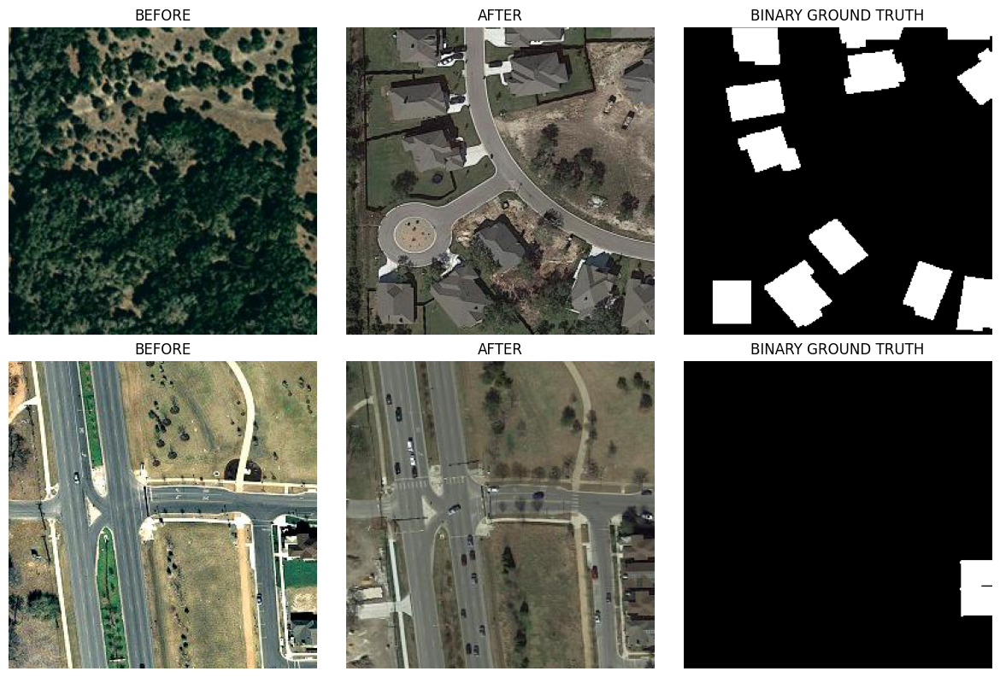


PREPROCESSING COMPLETED SUCCESSFULLY!
Training Images: 509
Validation Images: 128
Training Patches: 8144
Validation Patches: 2048
Patch Size: 256
Augmentation: TRAIN ONLY
Image Normalization: ImageNet RGB
Mask Format: Binary 0/1
Train/Validation Leakage: NONE at image level
Official Test: UNTOUCHED

Ready Variables:
train_files, val_files, train_patches, val_patches,
train_ds, val_ds, train_loader, val_loader

No patch files were created.
Patches are loaded on demand.


In [4]:

# ================================================================
# LEVIR-CD+ | DATA CLEANING + SPLITTING + PATCH PREPROCESSING
# Kaggle GPU Ready | Test Labels Untouched
# ================================================================

import random
from pathlib import Path
from collections import defaultdict, OrderedDict

import numpy as np
import pandas as pd
import cv2
from PIL import Image
import matplotlib.pyplot as plt

import torch
from torch.utils.data import (
    Dataset, DataLoader, Sampler, get_worker_info
)

from sklearn.model_selection import train_test_split
from tqdm.auto import tqdm
from IPython.display import display
import albumentations as A

# ================================================================
# 1. CONFIGURATION
# ================================================================

ROOT = Path(
    "/kaggle/input/datasets/mdrifaturrahman33/"
    "levir-cd-change-detection/LEVIR-CD+"
)

PATCH_SIZE = 256
VAL_FRACTION = 0.20
SEED = 42

BATCH_SIZE = 32
NUM_WORKERS = 2

MASK_THRESHOLD = 127
CACHE_IMAGES = 2
PHOTO_AUGMENT = True

# ImageNet RGB normalization
MEAN = np.array(
    [0.485, 0.456, 0.406],
    dtype=np.float32
).reshape(1, 1, 3)

STD = np.array(
    [0.229, 0.224, 0.225],
    dtype=np.float32
).reshape(1, 1, 3)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert ROOT.is_dir(), f"Dataset not found: {ROOT}"

print("=" * 72)
print("LEVIR-CD+ PREPROCESSING PIPELINE")
print("=" * 72)

# ================================================================
# 2. FILE INTEGRITY VERIFICATION
# ================================================================

names = {}

for split in ["train", "test"]:

    for folder in ["A", "B", "label"]:

        folder_path = ROOT / split / folder

        if not folder_path.is_dir():
            raise FileNotFoundError(folder_path)

        names[(split, folder)] = {
            f.name for f in folder_path.glob("*.png")
        }

for split in ["train", "test"]:

    a, b, m = (
        names[(split, key)]
        for key in ["A", "B", "label"]
    )

    print(
        f"{split.upper():5s}: "
        f"A={len(a)}, B={len(b)}, "
        f"label={len(m)}, "
        f"matched={len(a & b & m)}"
    )

    if a != b or a != m:

        raise RuntimeError(
            f"{split}: mismatched filenames"
        )

assert not (
    names[("train", "A")]
    & names[("test", "A")]
)

print("\nFilename Integrity: PASSED")
print("Test images and masks: NOT OPENED")

# ================================================================
# 3. DATA CLEANING + PATCH METADATA
# ================================================================

meta = []
patch_rows = []
bad_files = []

raw_value_counts = np.zeros(
    256, dtype=np.int64
)

for name in tqdm(
    sorted(names[("train", "A")]),
    desc="Cleaning and indexing training data"
):

    pa, pb, pm = (
        ROOT / "train" / folder / name
        for folder in ["A", "B", "label"]
    )

    try:

        with Image.open(pa) as im_a, Image.open(pb) as im_b:

            wh_a = im_a.size
            wh_b = im_b.size

        original = cv2.imread(
            str(pm),
            cv2.IMREAD_UNCHANGED
        )

        if original is None:
            raise ValueError("Unreadable mask")

        # Check multi-channel masks
        if original.ndim == 3:

            if original.shape[2] < 3 or not (
                np.array_equal(
                    original[:, :, 0],
                    original[:, :, 1]
                )
                and np.array_equal(
                    original[:, :, 0],
                    original[:, :, 2]
                )
            ):
                raise ValueError(
                    "Mask channels differ"
                )

            original = original[:, :, 0]

        if original.ndim != 2 or original.dtype != np.uint8:

            raise ValueError(
                "Mask must be 8-bit single-channel"
            )

        h, w = original.shape

        if wh_a != (w, h) or wh_b != (w, h):

            raise ValueError(
                "Before/After/Mask dimension mismatch"
            )

        if h % PATCH_SIZE or w % PATCH_SIZE:

            raise ValueError(
                "Image size not divisible by patch size"
            )

        # --------------------------------------------------------
        # Audit original mask values
        # --------------------------------------------------------

        counts = np.bincount(
            original.ravel(),
            minlength=256
        )

        unusual = (
            set(np.flatnonzero(counts))
            - {0, 156, 254, 255}
        )

        if unusual:

            raise ValueError(
                f"Unexpected mask values: {sorted(unusual)}"
            )

        raw_value_counts += counts

        # --------------------------------------------------------
        # Binary Mask Cleaning
        # --------------------------------------------------------

        # 0   -> No Change
        # 156 -> Change (provisional threshold convention)
        # 254 -> Change
        # 255 -> Change

        binary = (
            original > MASK_THRESHOLD
        ).astype(np.uint8)

        changed_pixels = int(binary.sum())

        change_percent = (
            100.0 * binary.mean()
        )

        # --------------------------------------------------------
        # Image-level change categories for stratification
        # --------------------------------------------------------

        if change_percent == 0:
            category = "zero"

        elif change_percent < 1:
            category = "0-1%"

        elif change_percent < 5:
            category = "1-5%"

        elif change_percent < 10:
            category = "5-10%"

        else:
            category = "10%+"

        meta.append({
            "filename": name,
            "height": h,
            "width": w,
            "changed_pixels": changed_pixels,
            "change_pct": change_percent,
            "stratum": category
        })

        # --------------------------------------------------------
        # Non-overlapping 256x256 patch indexing
        # --------------------------------------------------------

        for y0 in range(0, h, PATCH_SIZE):

            for x0 in range(0, w, PATCH_SIZE):

                patch_mask = binary[
                    y0:y0 + PATCH_SIZE,
                    x0:x0 + PATCH_SIZE
                ]

                cp = int(patch_mask.sum())

                patch_rows.append({
                    "filename": name,
                    "y": y0,
                    "x": x0,
                    "changed_pixels": cp,
                    "change_pct": (
                        100 * cp / (PATCH_SIZE ** 2)
                    )
                })

    except Exception as e:

        bad_files.append(
            (name, str(e))
        )

info = pd.DataFrame(meta)
patch_info = pd.DataFrame(patch_rows)

if info.empty:
    raise RuntimeError("No valid training images found.")

print("\n" + "=" * 72)
print("DATA CLEANING SUMMARY")
print("=" * 72)

print("Valid Image Triplets:", len(info))
print("Quarantined Triplets:", len(bad_files))

if bad_files:

    display(
        pd.DataFrame(
            bad_files,
            columns=["Filename", "Reason"]
        ).head(20)
    )

original_counts = {
    int(v): int(raw_value_counts[v])
    for v in np.flatnonzero(raw_value_counts)
}

print("Original Mask Pixel Counts:")
print(original_counts)

gray_fraction = (
    100.0 * (
        raw_value_counts[156] + raw_value_counts[254]
    ) / raw_value_counts.sum()
)

print(
    "Nonstandard Gray Pixel Fraction (%):",
    round(gray_fraction, 6)
)

print("Binary Cleaning Rule: mask > 127 => 1")
print("No original files modified.")

# ================================================================
# 4. IMAGE-LEVEL TRAIN / VALIDATION SPLIT
# ================================================================

stratum_sizes = info["stratum"].value_counts()

can_stratify = (
    stratum_sizes.min() >= 2
    and round(len(info) * VAL_FRACTION) >= len(stratum_sizes)
)

stratify_labels = (
    info["stratum"]
    if can_stratify else None
)

train_files, val_files = train_test_split(
    info["filename"].tolist(),
    test_size=VAL_FRACTION,
    random_state=SEED,
    stratify=stratify_labels
)

train_files = sorted(train_files)
val_files = sorted(val_files)

assert set(train_files).isdisjoint(
    set(val_files)
)

assert (
    set(train_files) | set(val_files)
) == set(info["filename"])

assert not (
    (set(train_files) | set(val_files))
    & names[("test", "A")]
)

info["split"] = np.where(
    info["filename"].isin(val_files),
    "Validation",
    "Train"
)

print("\n" + "=" * 72)
print("TRAIN / VALIDATION SPLITTING")
print("=" * 72)

print("Random Seed:", SEED)
print("Training Images:", len(train_files))
print("Validation Images:", len(val_files))
print("Test Images:", len(names[("test", "A")]))

print("\nImage-Level Statistics:")

display(
    info.groupby(
        "split", as_index=False
    ).agg(
        Images=("filename", "count"),
        Changed_Pixels=("changed_pixels", "sum"),
        Mean_Change_Percent=("change_pct", "mean"),
        Median_Change_Percent=("change_pct", "median")
    ).round(3)
)

print("\nChange-Rate Stratification:")

display(
    pd.crosstab(
        info["stratum"],
        info["split"]
    )
)

print("\nImage-Level Leakage: NONE")

# ================================================================
# 5. CREATE TRAIN AND VALIDATION PATCH MANIFESTS
# ================================================================

train_patches = (
    patch_info[
        patch_info.filename.isin(train_files)
    ]
    .sort_values(["filename", "y", "x"])
    .reset_index(drop=True)
)

val_patches = (
    patch_info[
        patch_info.filename.isin(val_files)
    ]
    .sort_values(["filename", "y", "x"])
    .reset_index(drop=True)
)

assert (
    len(train_patches) + len(val_patches)
    == len(patch_info)
)

print("\n" + "=" * 72)
print("256x256 PATCH PREPROCESSING")
print("=" * 72)

print("Training Patches:", len(train_patches))
print("Validation Patches:", len(val_patches))
print("Total Patches:", len(patch_info))

for title, df in [
    ("Train", train_patches),
    ("Validation", val_patches)
]:

    empty = int(
        (df.changed_pixels == 0).sum()
    )

    positive = int(
        (df.changed_pixels > 0).sum()
    )

    pixel_rate = (
        100 * df.changed_pixels.sum()
        / (len(df) * PATCH_SIZE ** 2)
    )

    print(f"\n{title}:")
    print("  Zero-Change Patches:", empty)
    print("  Changed Patches:", positive)
    print("  Changed Pixel Rate:", round(pixel_rate, 3), "%")

# ================================================================
# 6. PYTORCH PATCH DATASET
# ================================================================

class LEVIRPatchDataset(Dataset):

    def __init__(
        self,
        manifest,
        train=False,
        cache_size=2
    ):

        self.rows = manifest[
            ["filename", "y", "x"]
        ].to_dict("records")

        self.train = train
        self.cache_size = cache_size
        self.cache = OrderedDict()

        # Geometric transforms: same on both images and mask
        self.geo_aug = A.Compose(
            [
                A.HorizontalFlip(p=0.5),
                A.VerticalFlip(p=0.5),
                A.RandomRotate90(p=0.5)
            ],
            additional_targets={
                "after": "image"
            }
        ) if train else None

        # Mild, independent illumination augmentation
        self.photo_aug = A.RandomBrightnessContrast(
            brightness_limit=0.10,
            contrast_limit=0.10,
            p=0.20
        ) if (train and PHOTO_AUGMENT) else None

    def __len__(self):
        return len(self.rows)

    def _triplet(self, filename):

        if filename in self.cache:

            self.cache.move_to_end(filename)
            return self.cache[filename]

        base = ROOT / "train"

        before = cv2.imread(
            str(base / "A" / filename),
            cv2.IMREAD_COLOR
        )

        after = cv2.imread(
            str(base / "B" / filename),
            cv2.IMREAD_COLOR
        )

        mask = cv2.imread(
            str(base / "label" / filename),
            cv2.IMREAD_GRAYSCALE
        )

        if before is None or after is None or mask is None:

            raise RuntimeError(
                f"Cannot load triplet: {filename}"
            )

        before = cv2.cvtColor(
            before,
            cv2.COLOR_BGR2RGB
        )

        after = cv2.cvtColor(
            after,
            cv2.COLOR_BGR2RGB
        )

        mask = (
            mask > MASK_THRESHOLD
        ).astype(np.uint8)

        self.cache[filename] = (
            before, after, mask
        )

        if len(self.cache) > self.cache_size:
            self.cache.popitem(last=False)

        return before, after, mask

    def __getitem__(self, idx):

        row = self.rows[int(idx)]

        filename = row["filename"]
        y0 = int(row["y"])
        x0 = int(row["x"])

        a, b, mask = self._triplet(filename)

        # Extract the exact same spatial patch
        a = np.ascontiguousarray(
            a[
                y0:y0 + PATCH_SIZE,
                x0:x0 + PATCH_SIZE
            ]
        )

        b = np.ascontiguousarray(
            b[
                y0:y0 + PATCH_SIZE,
                x0:x0 + PATCH_SIZE
            ]
        )

        mask = np.ascontiguousarray(
            mask[
                y0:y0 + PATCH_SIZE,
                x0:x0 + PATCH_SIZE
            ]
        )

        # ----------------------------------------------
        # Training augmentation only
        # ----------------------------------------------

        if self.train:

            aug = self.geo_aug(
                image=a,
                after=b,
                mask=mask
            )

            a = aug["image"]
            b = aug["after"]
            mask = aug["mask"]

            if self.photo_aug is not None:

                a = self.photo_aug(
                    image=a
                )["image"]

                b = self.photo_aug(
                    image=b
                )["image"]

        # ----------------------------------------------
        # RGB normalization
        # ----------------------------------------------

        a = (
            a.astype(np.float32) / 255.0 - MEAN
        ) / STD

        b = (
            b.astype(np.float32) / 255.0 - MEAN
        ) / STD

        before_t = torch.from_numpy(
            np.ascontiguousarray(
                a.transpose(2, 0, 1)
            )
        )

        after_t = torch.from_numpy(
            np.ascontiguousarray(
                b.transpose(2, 0, 1)
            )
        )

        mask_t = torch.from_numpy(
            np.ascontiguousarray(
                mask[None].astype(np.float32)
            )
        )

        return {
            "before": before_t,
            "after": after_t,
            "mask": mask_t,
            "filename": filename,
            "y": y0,
            "x": x0
        }

# ================================================================
# 7. IMAGE-GROUPED BATCH SAMPLER
# Avoid repeatedly decoding the same 1024x1024 image.
# ================================================================

class ByImageBatchSampler(Sampler):

    def __init__(
        self,
        ds,
        batch_size,
        shuffle,
        seed=42
    ):

        self.size = batch_size
        self.shuffle = shuffle
        self.seed = seed
        self.epoch = 0

        groups = defaultdict(list)

        for i, row in enumerate(ds.rows):
            groups[row["filename"]].append(i)

        self.groups = list(groups.values())
        self.length = len(ds)

    def __len__(self):

        return (
            self.length + self.size - 1
        ) // self.size

    def __iter__(self):

        rng = np.random.default_rng(
            self.seed + self.epoch
        )

        self.epoch += 1

        order = np.arange(
            len(self.groups)
        )

        if self.shuffle:
            rng.shuffle(order)

        batch = []

        for gi in order:

            indices = self.groups[int(gi)].copy()

            if self.shuffle:
                rng.shuffle(indices)

            batch.extend(indices)

            while len(batch) >= self.size:

                yield batch[:self.size]

                batch = batch[self.size:]

        if batch:
            yield batch

# ================================================================
# 8. DATASET OBJECTS AND DATALOADERS
# ================================================================

train_ds = LEVIRPatchDataset(
    train_patches,
    train=True,
    cache_size=CACHE_IMAGES
)

val_ds = LEVIRPatchDataset(
    val_patches,
    train=False,
    cache_size=CACHE_IMAGES
)

def seed_worker(worker_id):

    seed = torch.initial_seed() % 2**32

    np.random.seed(seed)
    random.seed(seed)

    ds = get_worker_info().dataset

    if (
        ds.geo_aug is not None
        and hasattr(ds.geo_aug, "set_random_seed")
    ):
        ds.geo_aug.set_random_seed(seed)

    if (
        ds.photo_aug is not None
        and hasattr(ds.photo_aug, "set_random_seed")
    ):
        ds.photo_aug.set_random_seed(seed + 1)


worker_kwargs = {
    "num_workers": NUM_WORKERS,
    "pin_memory": torch.cuda.is_available(),
    "worker_init_fn": seed_worker if NUM_WORKERS else None
}

if NUM_WORKERS:
    worker_kwargs["persistent_workers"] = True

train_loader = DataLoader(
    train_ds,
    batch_sampler=ByImageBatchSampler(
        train_ds,
        BATCH_SIZE,
        shuffle=True,
        seed=SEED
    ),
    **worker_kwargs
)

val_loader = DataLoader(
    val_ds,
    batch_sampler=ByImageBatchSampler(
        val_ds,
        BATCH_SIZE,
        shuffle=False,
        seed=SEED
    ),
    **worker_kwargs
)

# ================================================================
# 9. BATCH VERIFICATION
# ================================================================

print("\n" + "=" * 72)
print("DATALOADER BATCH VERIFICATION")
print("=" * 72)

batch = next(iter(train_loader))

# 6-channel input for the baseline U-Net
inputs_6ch = torch.cat(
    [
        batch["before"],
        batch["after"]
    ],
    dim=1
)

print(
    "Before Shape:",
    tuple(batch["before"].shape)
)

print(
    "After Shape:",
    tuple(batch["after"].shape)
)

print(
    "6-Channel U-Net Input:",
    tuple(inputs_6ch.shape)
)

print(
    "Ground Truth Mask:",
    tuple(batch["mask"].shape)
)

print(
    "Mask Unique Values:",
    torch.unique(batch["mask"]).tolist()
)

print(
    "Batch Changed Pixel Rate (%):",
    round(
        100 * batch["mask"].mean().item(),
        3
    )
)

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))

assert inputs_6ch.shape[1] == 6
assert batch["mask"].shape[1] == 1

assert set(
    torch.unique(batch["mask"]).tolist()
).issubset({0.0, 1.0})

# ================================================================
# 10. VERIFY PREPROCESSED SAMPLES VISUALLY
# ================================================================

positive_val_ids = np.flatnonzero(
    val_patches["changed_pixels"].to_numpy() > 0
)

if len(positive_val_ids) >= 2:

    preview_ids = positive_val_ids[:2]

else:

    preview_ids = list(
        range(min(2, len(val_ds)))
    )

fig, axs = plt.subplots(
    len(preview_ids),
    3,
    figsize=(12, 4 * len(preview_ids)),
    squeeze=False
)

for row, idx in enumerate(preview_ids):

    sample = val_ds[int(idx)]

    for j, field in enumerate(
        ["before", "after"]
    ):

        image = (
            sample[field]
            .permute(1, 2, 0)
            .numpy()
            * STD + MEAN
        )

        axs[row, j].imshow(
            np.clip(image, 0, 1)
        )

        axs[row, j].set_title(
            field.upper()
        )

    axs[row, 2].imshow(
        sample["mask"][0],
        cmap="gray",
        vmin=0,
        vmax=1
    )

    axs[row, 2].set_title(
        "BINARY GROUND TRUTH"
    )

    for ax in axs[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

# ================================================================
# FINAL SUMMARY
# ================================================================

print("\n" + "=" * 72)
print("PREPROCESSING COMPLETED SUCCESSFULLY!")
print("=" * 72)

print("Training Images:", len(train_files))
print("Validation Images:", len(val_files))
print("Training Patches:", len(train_patches))
print("Validation Patches:", len(val_patches))

print("Patch Size:", PATCH_SIZE)
print("Augmentation: TRAIN ONLY")
print("Image Normalization: ImageNet RGB")
print("Mask Format: Binary 0/1")
print("Train/Validation Leakage: NONE at image level")
print("Official Test: UNTOUCHED")

print("\nReady Variables:")
print(
    "train_files, val_files, train_patches, val_patches,"
)
print(
    "train_ds, val_ds, train_loader, val_loader"
)

print("\nNo patch files were created.")
print("Patches are loaded on demand.")
print("=" * 72)


SIAMESE U-NET CONFIGURATION
Device: cuda
Mixed Precision: True
Parameters: 4,416,673
Training Patches: 8144
Validation Patches: 2048
Encoder: Shared CNN
Fusion: Multi-Scale Absolute Difference
Decoder: U-Net
Input: Before RGB + After RGB
Output: Binary Change Logits
Threshold: 0.5
GPU Microbatch: 8

Forward Pass Verification: PASSED
Output Shape: (1, 1, 256, 256)

STARTING SIAMESE U-NET TRAINING


Train 1/35:   0%|          | 0/255 [00:00<?, ?it/s]

Validation 1/35:   0%|          | 0/64 [00:00<?, ?it/s]

Epoch 01 | Train Loss: 1.0877 | Val Loss: 0.9166 | IoU: 0.5555 | F1: 0.7142 | Precision: 0.7186 | Recall: 0.7099 | BEST


Train 2/35:   0%|          | 0/255 [00:00<?, ?it/s]

...

Validation 15/35:   0%|          | 0/64 [00:00<?, ?it/s]

Epoch 15 | Train Loss: 0.2414 | Val Loss: 0.3317 | IoU: 0.6964 | F1: 0.8210 | Precision: 0.9408 | Recall: 0.7283

Early Stopping at Epoch 15

BEST SIAMESE U-NET VALIDATION RESULTS
Best Epoch: 8
Best Change-Class IoU: 0.7329
Total Training Time (minutes): 32.42


,Epoch,Val IoU,Val F1,Val Precision,Val Recall,Val FP,Val FN
7,8,0.7329,0.8459,0.8818,0.8128,663761,1140346



Full Training History:


,Epoch,Train Loss,Train IoU,Val Loss,Val IoU,Val F1,Val Precision,Val Recall,Val FP,Val FN,LR
0,1,1.0877,0.2449,0.9166,0.5555,0.7142,0.7186,0.7099,1693273,1766830,0.0003
1,2,0.9623,0.3963,0.9666,0.3345,0.5014,0.8991,0.3476,237531,3973685,0.0003
2,3,0.8921,0.5300,1.0134,0.3173,0.4817,0.9689,0.3206,62722,4138231,0.0003
3,4,0.8421,0.6080,0.8642,0.5979,0.7483,0.9179,0.6317,344292,2243383,0.0003
4,5,0.8049,0.6574,0.8593,0.6159,0.7623,0.9329,0.6444,282146,2165960,0.0003
5,6,0.7841,0.6803,0.8257,0.6294,0.7725,0.9404,0.6555,253123,2098001,0.0003
6,7,0.7686,0.6984,0.8004,0.6953,0.8202,0.9223,0.7385,378948,1592640,0.0003
7,8,0.7466,0.7198,0.7406,0.7329,0.8459,0.8818,0.8128,663761,1140346,0.0003
8,9,0.7268,0.7148,0.5432,0.7200,0.8372,0.7861,0.8954,1483433,637373,0.0003
9,10,0.6052,0.7008,0.3469,0.7213,0.8381,0.8345,0.8417,1016512,964207,0.0003


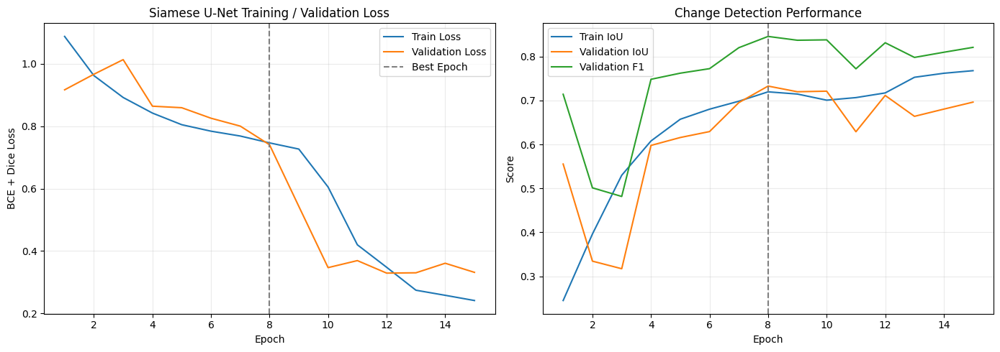


SIAMESE U-NET PREDICTION VISUALIZATION


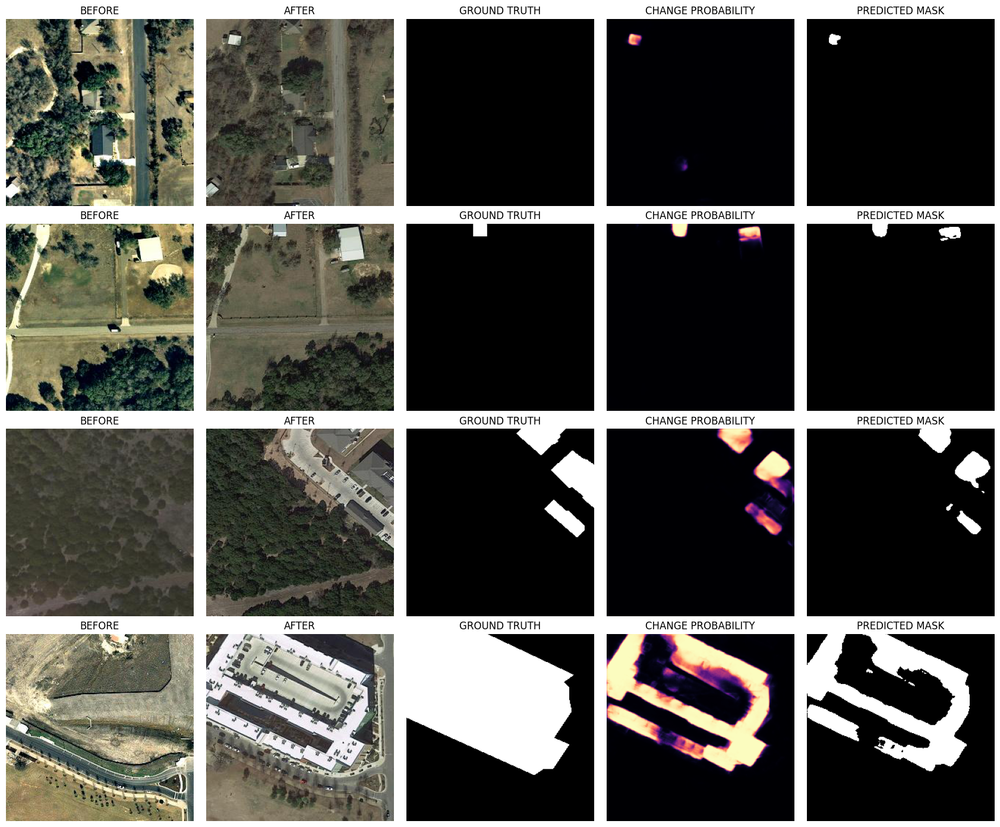


SIAMESE U-NET TRAINING COMPLETED
Best Epoch: 8
Best Validation IoU: 0.7329
Prediction Threshold: 0.5

Model: siamese_model
Training History: history_df
Best State: best_siamese_state

Official Test Set: NOT USED
No output files created.


In [5]:

# ================================================================
# LEVIR-CD+ | SIAMESE U-NET (FC-Siam-Diff style)
# TRAINING + VALIDATION + VISUALIZATION
# ================================================================

import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

from tqdm.auto import tqdm
from IPython.display import display

# ================================================================
# 1. CONFIGURATION
# ================================================================

SEED = 42
BASE_CHANNELS = 24

EPOCHS = 35
PATIENCE = 7
MIN_EPOCHS = 12

# Existing DataLoader batch = 32
# Split into smaller GPU microbatches to prevent OOM.
MICRO_BATCH = 8

LR = 3e-4
WEIGHT_DECAY = 1e-4

POS_WEIGHT = 2.0
THRESHOLD = 0.50

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

USE_AMP = DEVICE.type == "cuda"

required = [
    "train_loader",
    "val_loader",
    "val_ds",
    "val_patches"
]

for name in required:
    if name not in globals():
        raise RuntimeError(
            f"Missing {name}. Run preprocessing first."
        )

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if USE_AMP:
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

# ================================================================
# 2. CONVOLUTION BLOCK
# ================================================================

class ConvBlock(nn.Module):

    def __init__(self, in_ch, out_ch):

        super().__init__()

        self.layers = nn.Sequential(

            nn.Conv2d(
                in_ch, out_ch,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                out_ch, out_ch,
                kernel_size=3,
                padding=1,
                bias=False
            ),

            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.layers(x)

# ================================================================
# 3. SHARED SIAMESE ENCODER
# ================================================================

class SharedEncoder(nn.Module):

    def __init__(self, ch=24):

        super().__init__()

        self.blocks = nn.ModuleList([

            ConvBlock(3, ch),

            ConvBlock(ch, ch * 2),

            ConvBlock(ch * 2, ch * 4),

            ConvBlock(ch * 4, ch * 8),

            ConvBlock(ch * 8, ch * 16)

        ])

        self.pool = nn.MaxPool2d(2)

    def forward(self, x):

        features = []

        for i, block in enumerate(self.blocks):

            if i > 0:
                x = self.pool(x)

            x = block(x)

            features.append(x)

        return features

# ================================================================
# 4. U-NET DECODER BLOCK
# ================================================================

class UpFuse(nn.Module):

    def __init__(
        self,
        lower_ch,
        skip_ch,
        out_ch
    ):

        super().__init__()

        self.block = ConvBlock(
            lower_ch + skip_ch,
            out_ch
        )

    def forward(self, lower, skip):

        up = F.interpolate(
            lower,
            size=skip.shape[-2:],
            mode="bilinear",
            align_corners=False
        )

        fused = torch.cat(
            [up, skip],
            dim=1
        )

        return self.block(fused)

# ================================================================
# 5. COMPLETE SIAMESE U-NET
# ================================================================

class SiameseUNet(nn.Module):

    def __init__(self, ch=24):

        super().__init__()

        # One shared encoder for both images
        self.encoder = SharedEncoder(ch)

        # U-Net decoder
        self.up4 = UpFuse(
            ch * 16, ch * 8, ch * 8
        )

        self.up3 = UpFuse(
            ch * 8, ch * 4, ch * 4
        )

        self.up2 = UpFuse(
            ch * 4, ch * 2, ch * 2
        )

        self.up1 = UpFuse(
            ch * 2, ch, ch
        )

        self.head = nn.Conv2d(
            ch, 1, kernel_size=1
        )

        # Initial bias toward the majority No-Change class
        nn.init.constant_(
            self.head.bias, -2.5
        )

    def forward(self, before, after):

        if before.shape != after.shape:
            raise ValueError(
                "Before/After shapes must match."
            )

        batch_size = before.shape[0]

        # --------------------------------------------------------
        # STEP 1: SHARED FEATURE EXTRACTION
        # --------------------------------------------------------

        stacked = torch.cat(
            [before, after],
            dim=0
        )

        features = self.encoder(stacked)

        # --------------------------------------------------------
        # STEP 2: MULTI-SCALE FEATURE DIFFERENCE
        # --------------------------------------------------------

        differences = []

        for feat in features:

            f_before = feat[:batch_size]
            f_after = feat[batch_size:]

            diff = torch.abs(
                f_before - f_after
            )

            differences.append(diff)

        s1, s2, s3, s4, bottleneck = differences

        # --------------------------------------------------------
        # STEP 3: U-NET DECODER WITH SKIP CONNECTIONS
        # --------------------------------------------------------

        x = self.up4(bottleneck, s4)
        x = self.up3(x, s3)
        x = self.up2(x, s2)
        x = self.up1(x, s1)

        # --------------------------------------------------------
        # STEP 4: PIXEL-LEVEL CHANGE LOGITS
        # --------------------------------------------------------

        return self.head(x)

# ================================================================
# 6. MODEL INITIALIZATION
# ================================================================

siamese_model = SiameseUNet(
    BASE_CHANNELS
).to(DEVICE)

siamese_optimizer = torch.optim.AdamW(
    siamese_model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

siamese_scheduler = (
    torch.optim.lr_scheduler.ReduceLROnPlateau(
        siamese_optimizer,
        mode="max",
        factor=0.5,
        patience=3,
        min_lr=1e-6
    )
)

siamese_scaler = torch.amp.GradScaler(
    "cuda",
    enabled=USE_AMP
)

print("=" * 75)
print("SIAMESE U-NET CONFIGURATION")
print("=" * 75)

print("Device:", DEVICE)
print("Mixed Precision:", USE_AMP)

print(
    "Parameters:",
    f"{sum(p.numel() for p in siamese_model.parameters()):,}"
)

print("Training Patches:", len(train_loader.dataset))
print("Validation Patches:", len(val_loader.dataset))

print("Encoder: Shared CNN")
print("Fusion: Multi-Scale Absolute Difference")
print("Decoder: U-Net")
print("Input: Before RGB + After RGB")
print("Output: Binary Change Logits")
print("Threshold:", THRESHOLD)
print("GPU Microbatch:", MICRO_BATCH)

# ================================================================
# 7. BCE + DICE LOSS
# ================================================================

bce_fn = nn.BCEWithLogitsLoss(
    pos_weight=torch.tensor(
        [POS_WEIGHT],
        device=DEVICE
    )
)

def combined_loss(logits, target):

    # BCE already applies sigmoid internally
    bce = bce_fn(
        logits.float(),
        target.float()
    )

    probs = torch.sigmoid(
        logits.float()
    )

    target = target.float()

    dims = (1, 2, 3)

    intersection = (
        probs * target
    ).sum(dim=dims)

    denominator = (
        probs.sum(dim=dims)
        + target.sum(dim=dims)
    )

    dice_loss = 1 - (
        (
            2.0 * intersection + 1.0
        ) / (
            denominator + 1.0
        )
    ).mean()

    return bce + dice_loss

# ================================================================
# 8. METRIC CALCULATION
# ================================================================

def calculate_metrics(counts):

    tp, fp, fn, tn = counts.tolist()

    precision = tp / max(1.0, tp + fp)
    recall = tp / max(1.0, tp + fn)

    iou = tp / max(
        1.0,
        tp + fp + fn
    )

    f1 = (
        2 * tp
        / max(1.0, 2 * tp + fp + fn)
    )

    return {
        "IoU": iou,
        "F1": f1,
        "Precision": precision,
        "Recall": recall,
        "TP": int(tp),
        "FP": int(fp),
        "FN": int(fn),
        "Pred Change %": (
            100 * (tp + fp)
            / max(1.0, tp + fp + fn + tn)
        )
    }

# ================================================================
# 9. TRAINING / VALIDATION FUNCTION
# ================================================================

def run_epoch(loader, training, name):

    siamese_model.train(training)

    total_loss = 0.0
    total_patches = 0

    counts = torch.zeros(
        4,
        dtype=torch.float64,
        device=DEVICE
    )

    progress = tqdm(
        loader,
        desc=name,
        leave=False
    )

    for batch in progress:

        before_cpu = batch["before"]
        after_cpu = batch["after"]
        mask_cpu = batch["mask"]

        batch_n = int(mask_cpu.shape[0])

        if training:
            siamese_optimizer.zero_grad(
                set_to_none=True
            )

        # --------------------------------------------------------
        # GPU MICRO-BATCHING
        # --------------------------------------------------------

        for start in range(
            0,
            batch_n,
            MICRO_BATCH
        ):

            end = min(
                start + MICRO_BATCH,
                batch_n
            )

            micro_n = end - start

            before = before_cpu[
                start:end
            ].to(
                DEVICE,
                non_blocking=True
            )

            after = after_cpu[
                start:end
            ].to(
                DEVICE,
                non_blocking=True
            )

            mask = mask_cpu[
                start:end
            ].to(
                DEVICE,
                non_blocking=True
            )

            # ----------------------------------------------------
            # FORWARD + LOSS
            # ----------------------------------------------------

            with torch.set_grad_enabled(training):

                with torch.autocast(
                    device_type=DEVICE.type,
                    enabled=USE_AMP
                ):

                    logits = siamese_model(
                        before, after
                    )

                    loss = combined_loss(
                        logits, mask
                    )

                # ------------------------------------------------
                # BACKPROPAGATION
                # ------------------------------------------------

                if training:

                    scaled_loss = (
                        loss * micro_n / batch_n
                    )

                    siamese_scaler.scale(
                        scaled_loss
                    ).backward()

            total_loss += (
                loss.detach().item() * micro_n
            )

            total_patches += micro_n

            # ----------------------------------------------------
            # CONFUSION COUNTS
            # ----------------------------------------------------

            with torch.no_grad():

                pred = (
                    torch.sigmoid(logits.detach())
                    >= THRESHOLD
                )

                truth = mask >= 0.5

                counts[0] += (
                    pred & truth
                ).sum()

                counts[1] += (
                    pred & ~truth
                ).sum()

                counts[2] += (
                    ~pred & truth
                ).sum()

                counts[3] += (
                    ~pred & ~truth
                ).sum()

        # --------------------------------------------------------
        # ONE OPTIMIZER STEP PER ORIGINAL BATCH
        # --------------------------------------------------------

        if training:

            siamese_scaler.unscale_(
                siamese_optimizer
            )

            nn.utils.clip_grad_norm_(
                siamese_model.parameters(),
                max_norm=1.0
            )

            siamese_scaler.step(
                siamese_optimizer
            )

            siamese_scaler.update()

    metrics = calculate_metrics(counts)

    metrics["Loss"] = (
        total_loss / max(1, total_patches)
    )

    return metrics

# ================================================================
# 10. FORWARD PASS VERIFICATION
# ================================================================

siamese_model.eval()

with torch.no_grad():

    probe = next(iter(val_loader))

    before = probe["before"][:1].to(DEVICE)
    after = probe["after"][:1].to(DEVICE)

    logits = siamese_model(before, after)

    assert logits.shape == (
        1, 1, 256, 256
    )

print("\nForward Pass Verification: PASSED")
print("Output Shape:", tuple(logits.shape))

# ================================================================
# 11. MODEL TRAINING
# ================================================================

print("\n" + "=" * 75)
print("STARTING SIAMESE U-NET TRAINING")
print("=" * 75)

siamese_history = []

best_iou = -1.0
best_epoch = 0
stale = 0

best_siamese_state = None

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    train_result = run_epoch(
        train_loader,
        training=True,
        name=f"Train {epoch}/{EPOCHS}"
    )

    val_result = run_epoch(
        val_loader,
        training=False,
        name=f"Validation {epoch}/{EPOCHS}"
    )

    siamese_scheduler.step(
        val_result["IoU"]
    )

    row = {
        "Epoch": epoch,

        "Train Loss": train_result["Loss"],
        "Train IoU": train_result["IoU"],

        "Val Loss": val_result["Loss"],
        "Val IoU": val_result["IoU"],
        "Val F1": val_result["F1"],

        "Val Precision": val_result["Precision"],
        "Val Recall": val_result["Recall"],

        "Val FP": val_result["FP"],
        "Val FN": val_result["FN"],

        "LR": siamese_optimizer.param_groups[0]["lr"]
    }

    siamese_history.append(row)

    improved = (
        val_result["IoU"] > best_iou + 1e-4
    )

    if improved:

        best_iou = val_result["IoU"]
        best_epoch = epoch
        stale = 0

        # Keep best checkpoint in memory only
        best_siamese_state = {
            k: v.detach().cpu().clone()
            for k, v in siamese_model.state_dict().items()
        }

    else:
        stale += 1

    print(
        f"Epoch {epoch:02d} | "
        f"Train Loss: {train_result['Loss']:.4f} | "
        f"Val Loss: {val_result['Loss']:.4f} | "
        f"IoU: {val_result['IoU']:.4f} | "
        f"F1: {val_result['F1']:.4f} | "
        f"Precision: {val_result['Precision']:.4f} | "
        f"Recall: {val_result['Recall']:.4f}"
        + (" | BEST" if improved else "")
    )

    if epoch >= MIN_EPOCHS and stale >= PATIENCE:

        print(
            f"\nEarly Stopping at Epoch {epoch}"
        )

        break

# ================================================================
# 12. RESTORE BEST MODEL
# ================================================================

siamese_model.load_state_dict(
    best_siamese_state
)

siamese_model.eval()

history_df = pd.DataFrame(
    siamese_history
)

print("\n" + "=" * 75)
print("BEST SIAMESE U-NET VALIDATION RESULTS")
print("=" * 75)

print("Best Epoch:", best_epoch)
print("Best Change-Class IoU:", round(best_iou, 5))

print(
    "Total Training Time (minutes):",
    round(
        (time.time() - training_start) / 60,
        2
    )
)

display(
    history_df.loc[
        history_df["Epoch"] == best_epoch,
        [
            "Epoch",
            "Val IoU",
            "Val F1",
            "Val Precision",
            "Val Recall",
            "Val FP",
            "Val FN"
        ]
    ].round(4)
)

print("\nFull Training History:")
display(history_df.round(4))

# ================================================================
# 13. TRAINING CURVES
# ================================================================

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5)
)

# Loss curves
axes[0].plot(
    history_df["Epoch"],
    history_df["Train Loss"],
    label="Train Loss"
)

axes[0].plot(
    history_df["Epoch"],
    history_df["Val Loss"],
    label="Validation Loss"
)

axes[0].axvline(
    best_epoch,
    linestyle="--",
    color="gray",
    label="Best Epoch"
)

axes[0].set_title(
    "Siamese U-Net Training / Validation Loss"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCE + Dice Loss")
axes[0].legend()
axes[0].grid(alpha=0.25)

# Segmentation metrics
axes[1].plot(
    history_df["Epoch"],
    history_df["Train IoU"],
    label="Train IoU"
)

axes[1].plot(
    history_df["Epoch"],
    history_df["Val IoU"],
    label="Validation IoU"
)

axes[1].plot(
    history_df["Epoch"],
    history_df["Val F1"],
    label="Validation F1"
)

axes[1].axvline(
    best_epoch,
    linestyle="--",
    color="gray"
)

axes[1].set_title(
    "Change Detection Performance"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Score")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

# ================================================================
# 14. VALIDATION PREDICTION VISUALIZATION
# ================================================================

print("\n" + "=" * 75)
print("SIAMESE U-NET PREDICTION VISUALIZATION")
print("=" * 75)

# Select validation patches with different change rates
change_percent = (
    val_patches.reset_index(drop=True)["change_pct"]
    .to_numpy()
)

categories = [
    change_percent == 0,
    (change_percent > 0) & (change_percent < 1),
    (change_percent >= 1) & (change_percent < 10),
    change_percent >= 10
]

selected_indices = []

for condition in categories:

    ids = np.flatnonzero(condition)

    if len(ids):
        selected_indices.append(
            int(ids[len(ids) // 2])
        )

if not selected_indices:
    selected_indices = [0]

rgb_mean = np.array(
    [0.485, 0.456, 0.406]
).reshape(1, 1, 3)

rgb_std = np.array(
    [0.229, 0.224, 0.225]
).reshape(1, 1, 3)

fig, axes = plt.subplots(
    len(selected_indices),
    5,
    figsize=(17, 3.5 * len(selected_indices)),
    squeeze=False
)

siamese_model.eval()

with torch.no_grad():

    for row, idx in enumerate(selected_indices):

        sample = val_ds[idx]

        before = sample["before"].unsqueeze(0).to(DEVICE)
        after = sample["after"].unsqueeze(0).to(DEVICE)

        with torch.autocast(
            device_type=DEVICE.type,
            enabled=USE_AMP
        ):

            logits = siamese_model(
                before, after
            )

        prob = (
            torch.sigmoid(logits.float())
            [0, 0].cpu().numpy()
        )

        pred = prob >= THRESHOLD

        gt = sample["mask"][0].numpy()

        a = np.clip(
            sample["before"].permute(1, 2, 0).numpy()
            * rgb_std + rgb_mean,
            0, 1
        )

        b = np.clip(
            sample["after"].permute(1, 2, 0).numpy()
            * rgb_std + rgb_mean,
            0, 1
        )

        images = [a, b, gt, prob, pred]

        titles = [
            "BEFORE",
            "AFTER",
            "GROUND TRUTH",
            "CHANGE PROBABILITY",
            "PREDICTED MASK"
        ]

        for col, (image, title) in enumerate(
            zip(images, titles)
        ):

            cmap = (
                "magma" if col == 3
                else "gray" if col in [2, 4]
                else None
            )

            axes[row, col].imshow(
                image,
                cmap=cmap,
                vmin=0 if col >= 2 else None,
                vmax=1 if col >= 2 else None
            )

            axes[row, col].set_title(title)
            axes[row, col].axis("off")

plt.tight_layout()
plt.show()

# ================================================================
# FINAL SUMMARY
# ================================================================

print("\n" + "=" * 75)
print("SIAMESE U-NET TRAINING COMPLETED")
print("=" * 75)

print("Best Epoch:", best_epoch)
print("Best Validation IoU:", round(best_iou, 4))
print("Prediction Threshold:", THRESHOLD)

print("\nModel: siamese_model")
print("Training History: history_df")
print("Best State: best_siamese_state")

print("\nOfficial Test Set: NOT USED")
print("No output files created.")

print("=" * 75)
